# APS 3: Tópicos Especiais I

Linyker Mendes Coelho, Sistemas de Informação, turma 4B.

Questão 1: filtros de suavização na `imagem1.png` e equalização de histograma na `imagem2.png`, usando OpenCV.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def mostrar(imagens, titulos, colunas=2, tamanho=(12, 9)):
    linhas = int(np.ceil(len(imagens) / colunas))
    fig, eixos = plt.subplots(linhas, colunas, figsize=tamanho)
    for eixo, img, titulo in zip(np.ravel(eixos), imagens, titulos):
        eixo.imshow(img, cmap='gray', vmin=0, vmax=255)
        eixo.set_title(titulo)
        eixo.axis('off')
    for eixo in np.ravel(eixos)[len(imagens):]:
        eixo.axis('off')
    plt.tight_layout()
    plt.show()

def nitidez(img):
    # variância do Laplaciano: quanto maior, mais bordas e detalhes finos a imagem tem
    return cv2.Laplacian(img, cv2.CV_64F).var()

## Imagem 1

A imagem é uma cartela de teste com várias regiões: círculos em tons de cinza, quadrados concêntricos, degradê, uma área de ruído, uma esfera, listras grossas e finas, um círculo fino sobre fundo preto, tijolos, xadrez, listras diagonais e quadrados coloridos. Ela é útil porque cada filtro afeta essas regiões de um jeito diferente. Vou trabalhar em tons de cinza.

(302, 410)


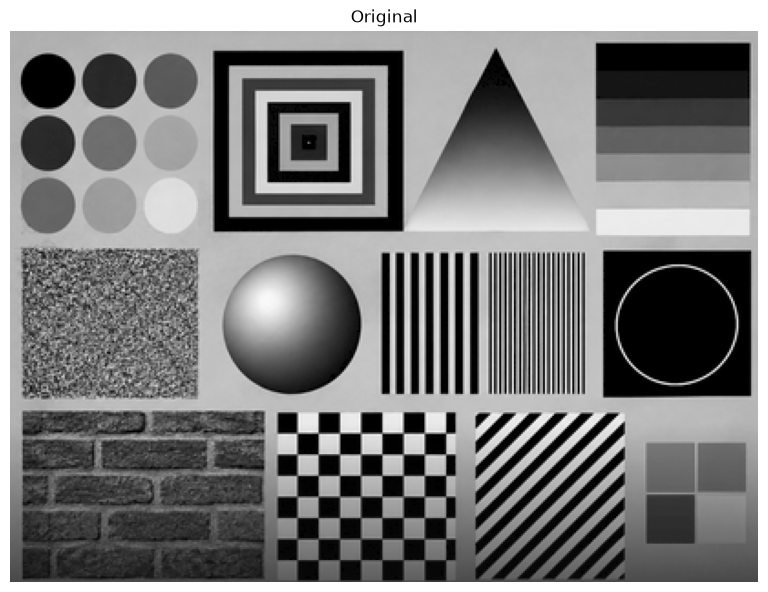

Nitidez original: 6698


In [2]:
img1 = cv2.imread('imagem1.png', cv2.IMREAD_GRAYSCALE)
print(img1.shape)
mostrar([img1], ['Original'], colunas=1, tamanho=(8, 6))
print('Nitidez original:', round(nitidez(img1)))

### Filtro da média

`cv2.blur` troca cada pixel pela média simples da vizinhança. Testei kernels 3x3, 5x5 e 9x9.

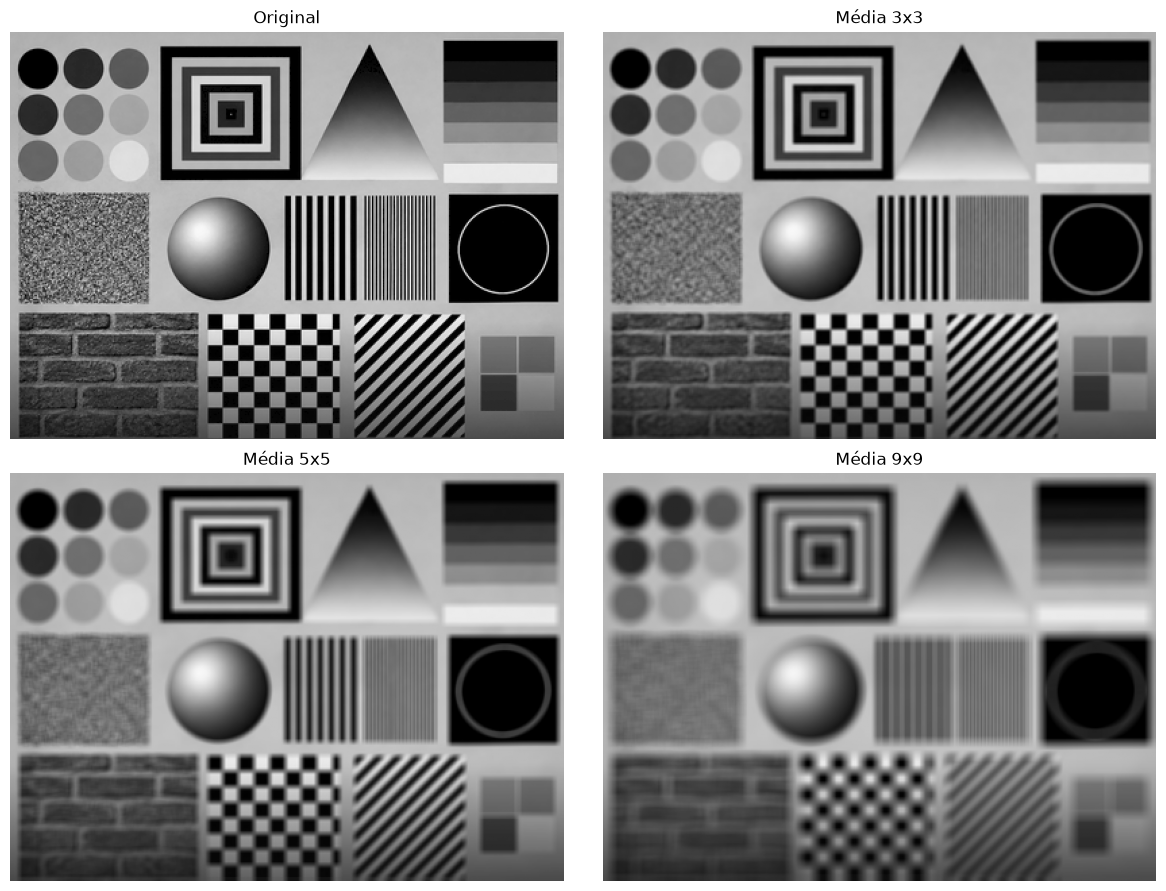

Média 3x3: nitidez = 420
Média 5x5: nitidez = 153
Média 9x9: nitidez = 54


In [3]:
media = {k: cv2.blur(img1, (k, k)) for k in (3, 5, 9)}
mostrar([img1] + list(media.values()), ['Original'] + [f'Média {k}x{k}' for k in media])
for k, img in media.items():
    print(f'Média {k}x{k}: nitidez = {nitidez(img):.0f}')

**Análise do filtro da média.** A imagem inteira fica borrada e o borrão cresce com o kernel. O ruído da área granulada diminui, mas vira uma mancha cinza em vez de sumir. As bordas perdem definição: os quadrados concêntricos, o xadrez e os tijolos ficam com contornos borrados. Nas listras finas e no círculo fino o efeito é pior, porque as linhas pretas e brancas se misturam e viram cinza. No 9x9 as listras finas quase somem. A nitidez medida cai de cerca de 6700 para 420 (3x3), 153 (5x5) e 54 (9x9), ou seja, é o filtro que mais destrói detalhe.

### Filtro da mediana

`cv2.medianBlur` troca cada pixel pela mediana da vizinhança, que é sempre um valor que já existia na imagem.

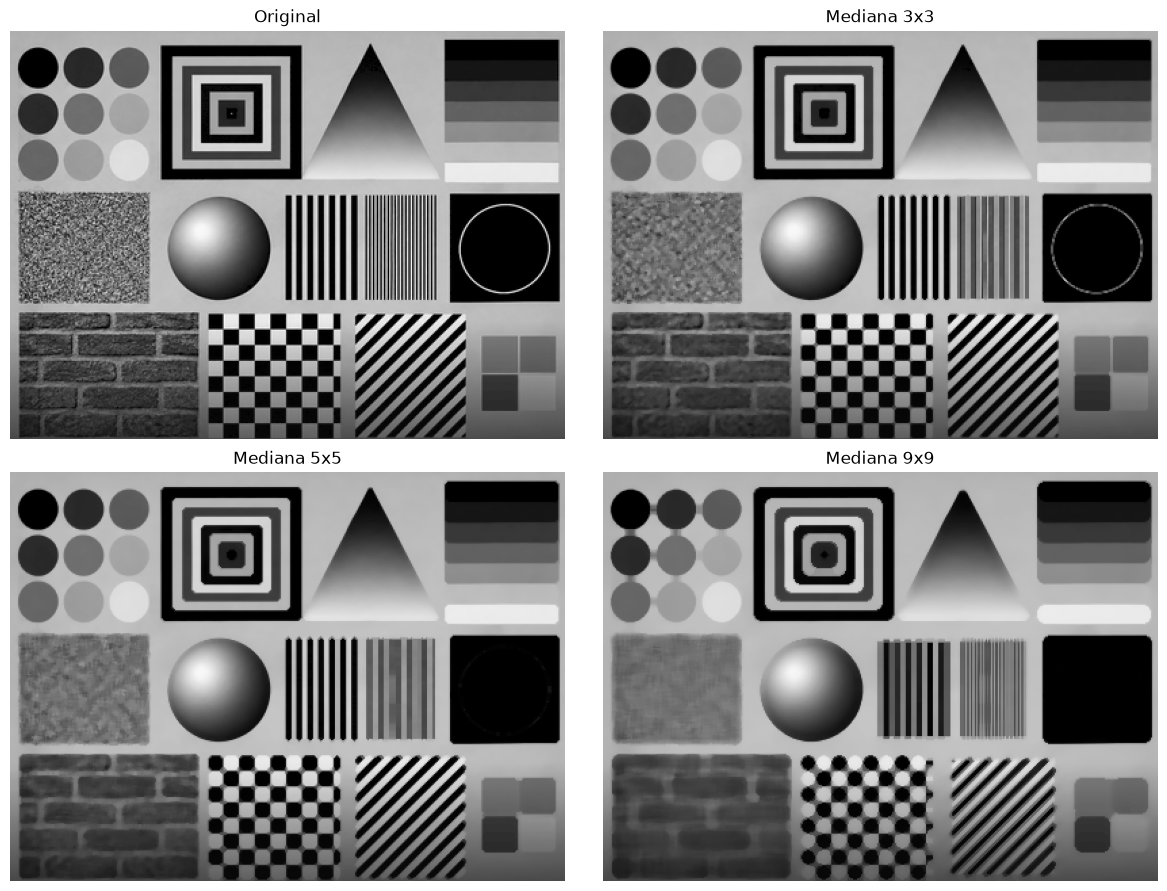

Mediana 3x3: nitidez = 2454
Mediana 5x5: nitidez = 2097
Mediana 9x9: nitidez = 1732


In [4]:
mediana = {k: cv2.medianBlur(img1, k) for k in (3, 5, 9)}
mostrar([img1] + list(mediana.values()), ['Original'] + [f'Mediana {k}x{k}' for k in mediana])
for k, img in mediana.items():
    print(f'Mediana {k}x{k}: nitidez = {nitidez(img):.0f}')

**Análise do filtro da mediana.** As bordas grandes continuam nítidas: os quadrados concêntricos, o xadrez e os círculos mantêm o contorno bem definido, e isso aparece na nitidez, que fica em 2454, 2097 e 1732, bem acima dos outros filtros. A área de ruído fica mais uniforme sem virar borrão. O problema está nos detalhes menores que o kernel: o círculo branco fino sobre o fundo preto praticamente desaparece, porque a linha tem poucos pixels de largura e a mediana a trata como ruído. As listras finas ficam deformadas, com aspecto quebrado, e os cantos dos quadrados ficam arredondados. No 9x9 a imagem começa a parecer uma pintura com manchas.

### Filtro gaussiano

`cv2.GaussianBlur` faz uma média ponderada, com peso maior para os pixels mais próximos do centro.

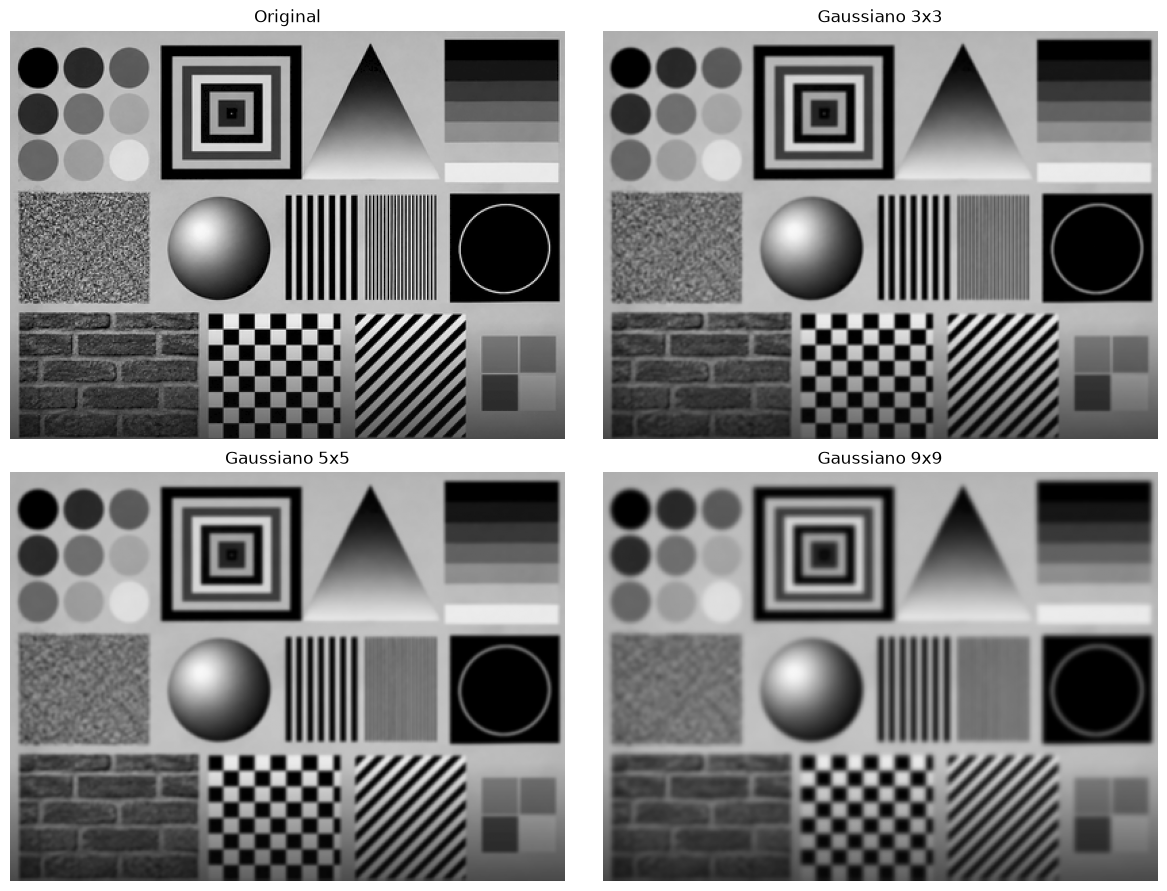

Gaussiano 3x3: nitidez = 580
Gaussiano 5x5: nitidez = 241
Gaussiano 9x9: nitidez = 71


In [5]:
gauss = {k: cv2.GaussianBlur(img1, (k, k), 0) for k in (3, 5, 9)}
mostrar([img1] + list(gauss.values()), ['Original'] + [f'Gaussiano {k}x{k}' for k in gauss])
for k, img in gauss.items():
    print(f'Gaussiano {k}x{k}: nitidez = {nitidez(img):.0f}')

**Análise do filtro gaussiano.** Também borra, mas de forma mais suave e natural que a média com o mesmo kernel. As bordas ficam com uma transição gradual em vez de um borrão chapado, e o círculo fino continua visível, só mais claro e espesso. O ruído é atenuado de forma parecida com a média. A nitidez fica em 580, 241 e 71, um pouco acima da média em cada tamanho, o que confirma que ele preserva um pouco mais de detalhe.

### Comparação entre os filtros

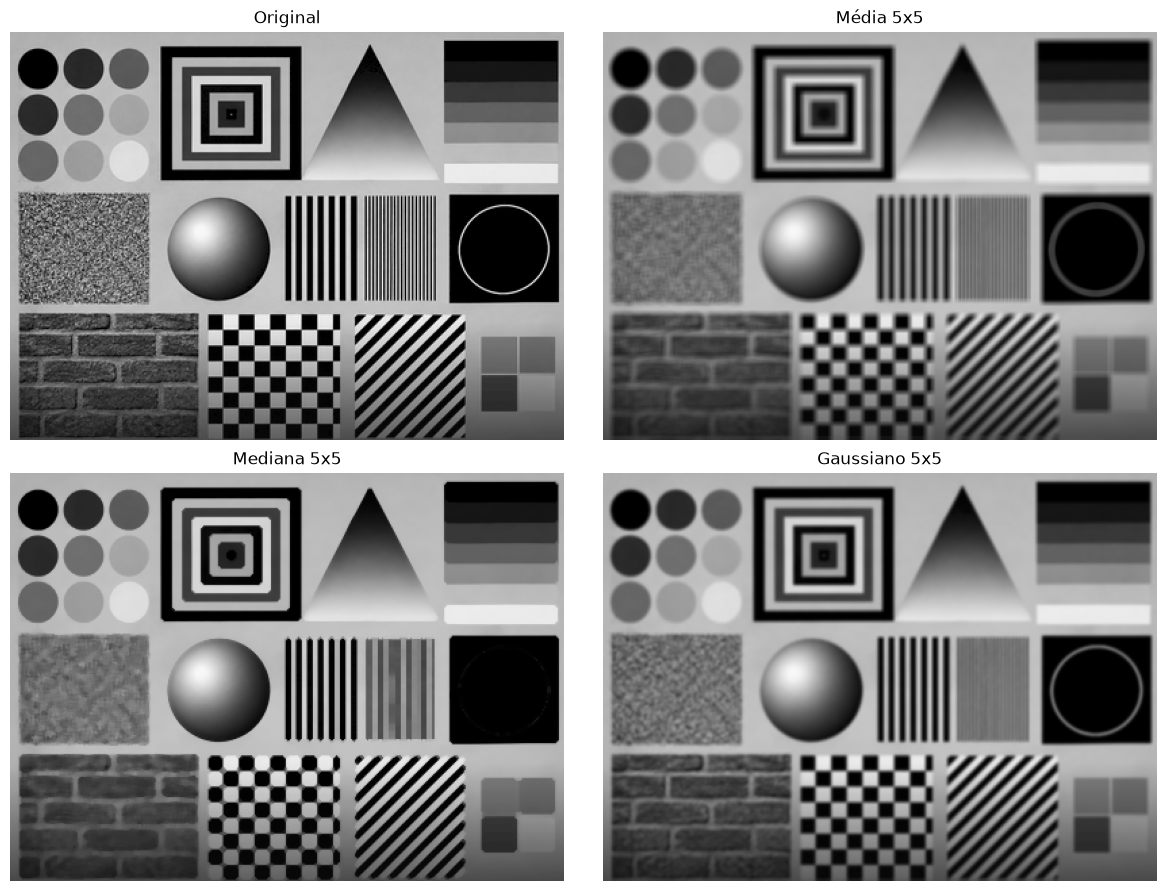

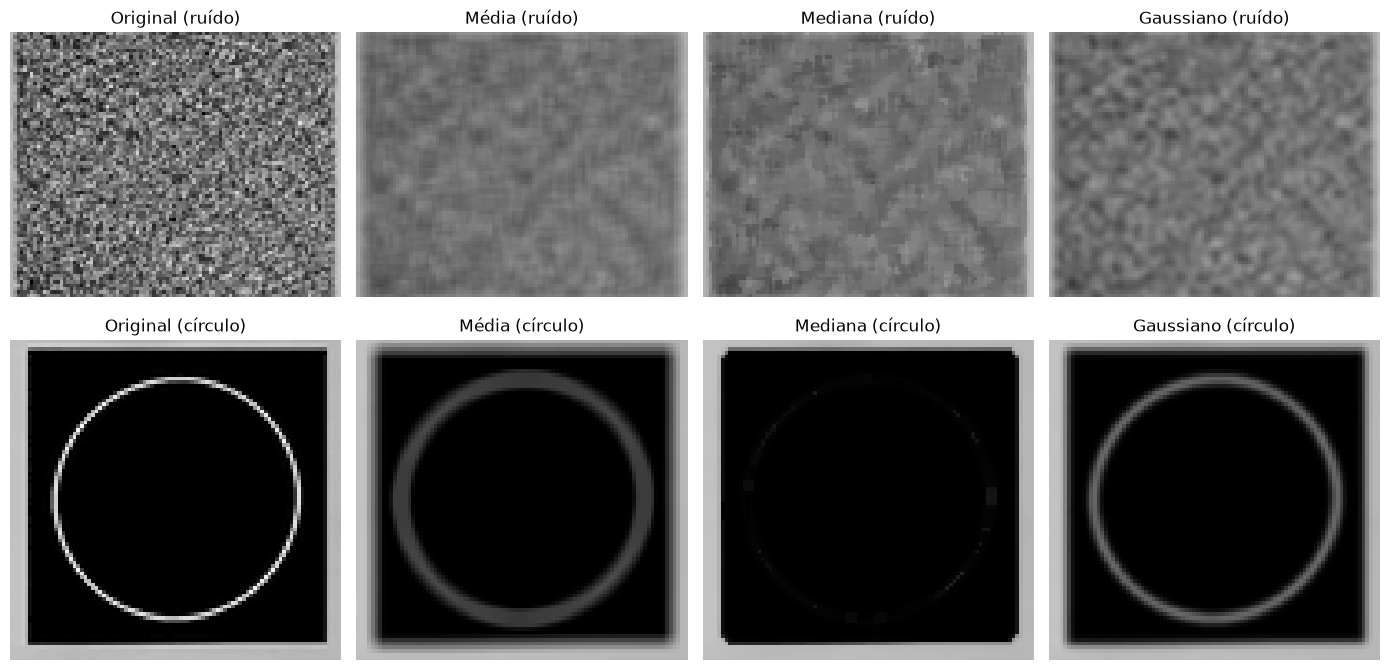

Original   nitidez =   6698   desvio na área de ruído = 36.7
Média      nitidez =    153   desvio na área de ruído = 13.8
Mediana    nitidez =   2097   desvio na área de ruído = 17.7
Gaussiano  nitidez =    241   desvio na área de ruído = 16.7


In [6]:
k = 5
mostrar([img1, media[k], mediana[k], gauss[k]],
        ['Original', f'Média {k}x{k}', f'Mediana {k}x{k}', f'Gaussiano {k}x{k}'])

# recortes da área de ruído e do círculo fino para ver melhor a diferença
ruido = (slice(120, 200), slice(5, 105))
circulo = (slice(118, 205), slice(320, 410))
imgs = [img1, media[k], mediana[k], gauss[k]]
nomes = ['Original', 'Média', 'Mediana', 'Gaussiano']
mostrar([i[ruido] for i in imgs] + [i[circulo] for i in imgs],
        [f'{n} (ruído)' for n in nomes] + [f'{n} (círculo)' for n in nomes], colunas=4, tamanho=(14, 7))

for nome, img in zip(nomes, imgs):
    print(f'{nome:10s} nitidez = {nitidez(img):6.0f}   desvio na área de ruído = {img[ruido].std():.1f}')

**Comparação.** Os três filtros reduzem o ruído (o desvio padrão da área granulada cai de 36,7 para algo entre 14 e 18), mas cada um paga um preço diferente:

- A média é a que mais borra. Suaviza tudo por igual e apaga detalhes finos e bordas junto com o ruído.
- O gaussiano tem resultado parecido com a média, porém mais suave e com um pouco mais de nitidez. Por dar mais peso ao centro, deforma menos as bordas.
- A mediana é a que melhor preserva bordas e contornos grandes, por isso a nitidez dela fica muito acima das outras. Em troca, apaga estruturas mais finas que o kernel, como o círculo fino, e distorce as listras finas.

Para ruído do tipo sal e pimenta, ou quando é importante manter bordas, a mediana é a melhor escolha. Para uma suavização geral antes de outra etapa (detecção de bordas, por exemplo), o gaussiano dá o resultado mais equilibrado. A média é a mais simples, mas a que mais perde informação.

## Imagem 2

A imagem 2 é uma superfície com crateras e relevo, com contraste muito baixo. O histograma mostra que os pixels estão concentrados numa faixa estreita de cinza.

In [7]:
img2 = cv2.imread('imagem2.png', cv2.IMREAD_GRAYSCALE)
print('mín:', img2.min(), 'máx:', img2.max(), 'média:', round(img2.mean(), 1), 'desvio:', round(img2.std(), 1))
print('98% dos pixels entre', np.percentile(img2, 1), 'e', np.percentile(img2, 99))

mín: 23 máx: 128 média: 72.3 desvio: 5.6
98% dos pixels entre 49.0 e 84.0


### Equalização de histograma global e CLAHE

`cv2.equalizeHist` redistribui os tons para ocupar toda a faixa de 0 a 255. Também testei o CLAHE (`cv2.createCLAHE`), que equaliza por blocos e limita o quanto o contraste pode aumentar.

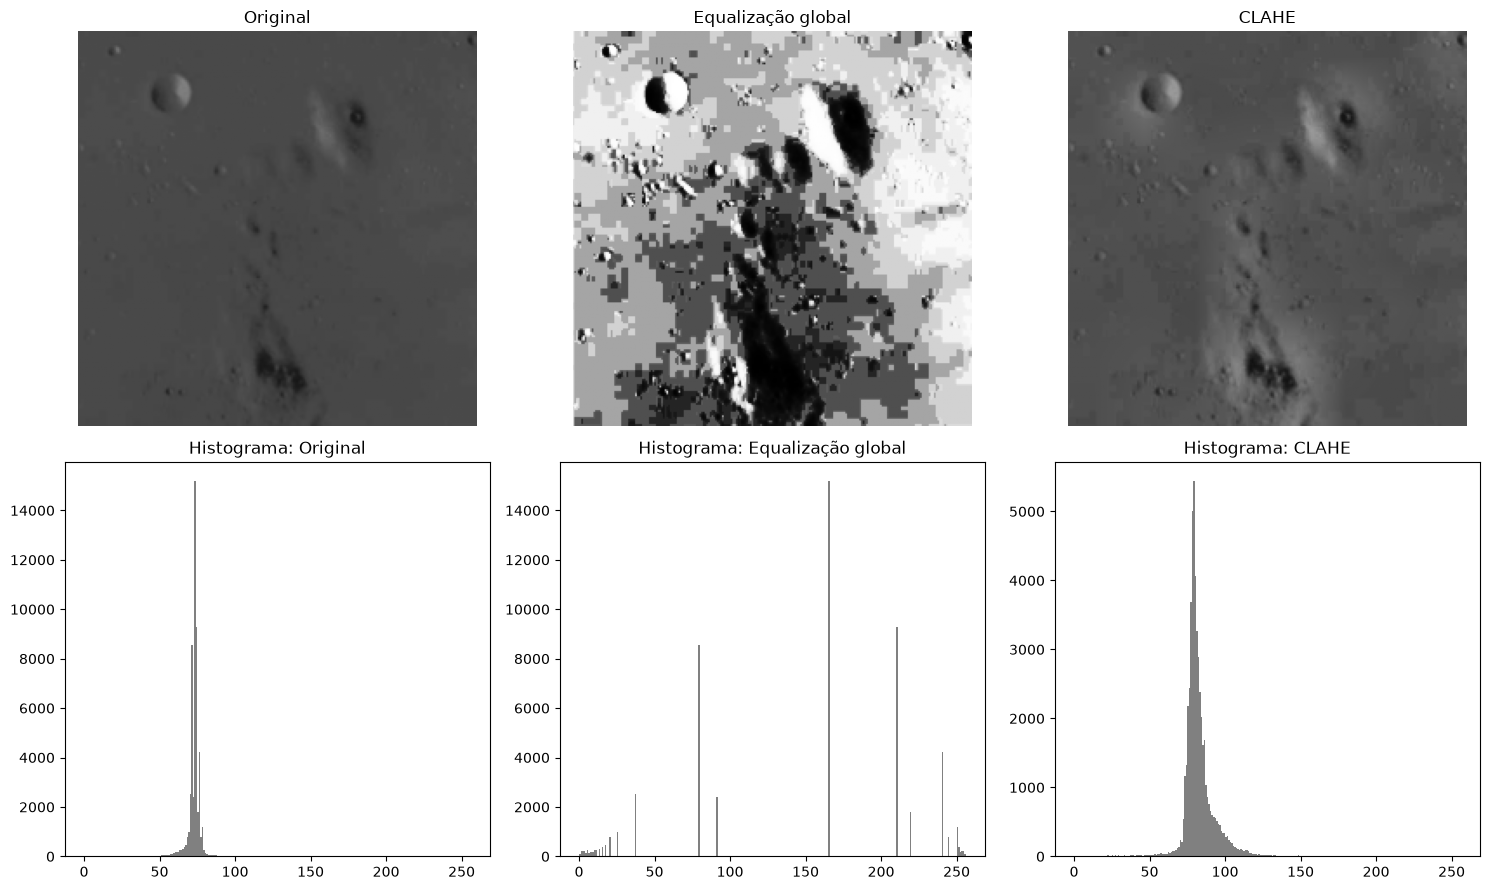

Original     mín= 23 máx=128 média=  72.3 desvio=  5.6
Equalização  mín=  0 máx=255 média= 147.3 desvio= 74.5
CLAHE        mín= 17 máx=155 média=  82.2 desvio= 10.5


In [8]:
eq = cv2.equalizeHist(img2)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img2)

fig, eixos = plt.subplots(2, 3, figsize=(15, 9))
for col, (img, titulo) in enumerate([(img2, 'Original'), (eq, 'Equalização global'), (clahe, 'CLAHE')]):
    eixos[0, col].imshow(img, cmap='gray', vmin=0, vmax=255)
    eixos[0, col].set_title(titulo)
    eixos[0, col].axis('off')
    eixos[1, col].hist(img.ravel(), bins=256, range=(0, 256), color='gray')
    eixos[1, col].set_title(f'Histograma: {titulo}')
plt.tight_layout()
plt.show()

for nome, img in [('Original', img2), ('Equalização', eq), ('CLAHE', clahe)]:
    print(f'{nome:12s} mín={img.min():3d} máx={img.max():3d} média={img.mean():6.1f} desvio={img.std():5.1f}')

**Análise da equalização.** Na original quase todos os pixels ficam entre 49 e 84, por isso a imagem parece um cinza uniforme e as crateras quase não aparecem.

Com a equalização global o histograma passa a ocupar de 0 a 255 e o desvio padrão sobe de 5,6 para 74,5. As crateras, as sombras e o relevo ficam muito mais visíveis, e a cratera grande em cima à esquerda aparece com borda clara. O efeito colateral é o exagero: a imagem fica com aparência de manchas e blocos, porque o filtro amplifica também o ruído e os artefatos de compressão que estavam escondidos na faixa estreita de cinza. Algumas áreas planas viram regiões quase brancas.

O CLAHE dá um resultado mais natural. O contraste sobe (desvio de 5,6 para 10,5), as crateras e o relevo ficam mais nítidos que na original, e a imagem não ganha os blocos da equalização global, porque o aumento de contraste é limitado em cada região. Para enxergar detalhe a equalização global mostra mais coisa, mas para uma imagem com aparência realista o CLAHE é melhor.